Eigenvalues: [-2.34135828e-17 -1.51071143e+00 -3.71083145e+00 -6.77845712e+00]
Stationary distribution: [0.15789474 0.31578947 0.31578947 0.21052632]
lambda_2: -1.5107114281899212
Numerical time when TV = 0.01: 2.8979906360210714
TV at numerical time: 0.010000000000000842
Asymptotic prefactor C: 0.79715416217886
Basic theoretical estimate: 3.0483453689801214
Corrected asymptotic estimate: 2.8982788595280273


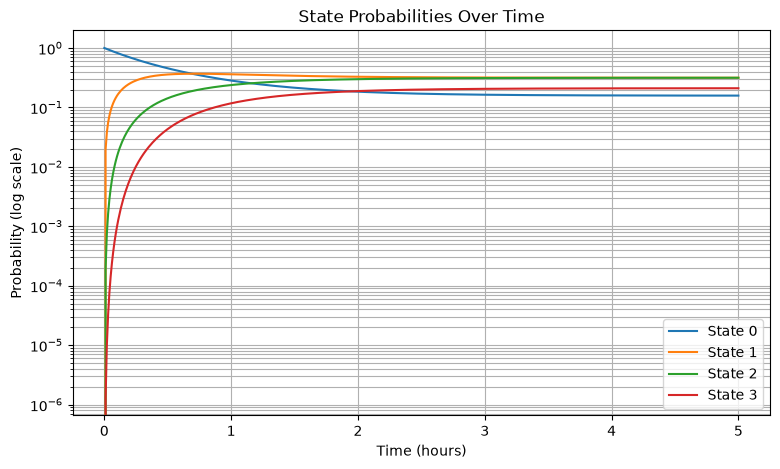

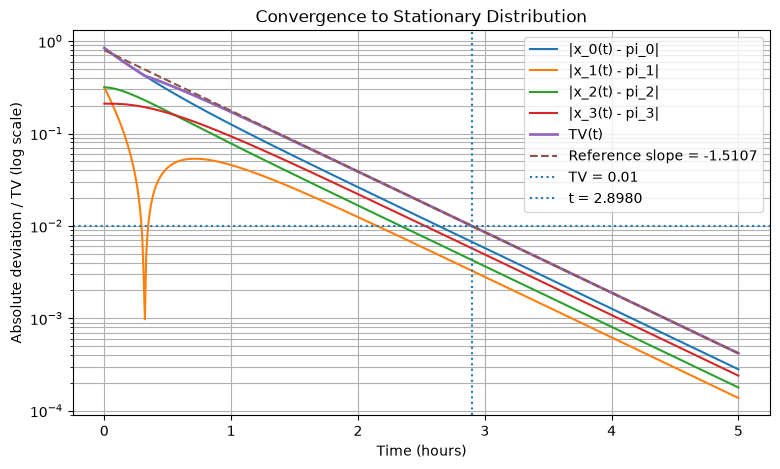

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import brentq
import os

# Rate matrix
Q = np.array([
    [-2,  2,  0,  0],
    [ 1, -3,  2,  0],
    [ 0,  2, -4,  2],
    [ 0,  0,  3, -3]
], dtype=float)

# Initial distribution: starting empty
x0 = np.array([1, 0, 0, 0], dtype=float)

# Stationary distribution
pi = np.array([3, 6, 6, 4], dtype=float) / 19

# Eigenvalues
eigenvalues = np.sort(np.linalg.eigvals(Q).real)[::-1]
lambda2 = eigenvalues[1]

# Probability distribution
def x(t):
    return x0 @ expm(t * Q)

# Total variation distance
def TV(t):
    return 0.5 * np.sum(np.abs(x(t) - pi))

# Time grid
times = np.linspace(0, 5, 501)

# Calculate probabilities and deviations
probabilities = np.array([x(t) for t in times])
deviations = np.abs(probabilities - pi)
tv_values = np.array([TV(t) for t in times])

# Find time when TV = 0.01
t_star = brentq(lambda t: TV(t) - 0.01, 2, 3)

# Asymptotic prefactor, evaluated at t = 5
C = TV(5) * np.exp(-lambda2 * 5)

# Theoretical estimates
t_basic = np.log(100) / abs(lambda2)
t_corrected = (np.log(100) + np.log(C)) / abs(lambda2)

# Print results
print("Eigenvalues:", eigenvalues)
print("Stationary distribution:", pi)
print("lambda_2:", lambda2)
print("Numerical time when TV = 0.01:", t_star)
print("TV at numerical time:", TV(t_star))
print("Asymptotic prefactor C:", C)
print("Basic theoretical estimate:", t_basic)
print("Corrected asymptotic estimate:", t_corrected)

# Plot 1: State probabilities on a logarithmic scale
plt.figure(figsize=(9, 5))

for i in range(4):
    plt.semilogy(times, probabilities[:, i],
                 label=f"State {i}")

plt.xlabel("Time (hours)")
plt.ylabel("Probability (log scale)")
plt.title("State Probabilities Over Time")
plt.legend()
plt.grid(True, which="both")
plt.savefig(os.path.expanduser("~/Downloads/HW 9 1.pdf"), bbox_inches="tight")

plt.show()


# Plot 2: Absolute deviations and TV on a logarithmic scale
plt.figure(figsize=(9, 5))

for i in range(4):
    plt.semilogy(times, deviations[:, i],
                 label=f"|x_{i}(t) - pi_{i}|")

plt.semilogy(times, tv_values, linewidth=2,
             label="TV(t)")

# Reference line with slope lambda_2
reference = C * np.exp(lambda2 * times)

plt.semilogy(times, reference, "--",
             label=f"Reference slope = {lambda2:.4f}")

plt.axhline(0.01, linestyle=":",
            label="TV = 0.01")

plt.axvline(t_star, linestyle=":",
            label=f"t = {t_star:.4f}")

plt.xlabel("Time (hours)")
plt.ylabel("Absolute deviation / TV (log scale)")
plt.title("Convergence to Stationary Distribution")
plt.legend()
plt.grid(True, which="both")
plt.savefig(os.path.expanduser("~/Downloads/HW 9 2.pdf"), bbox_inches="tight")

plt.show()

